<a href="https://colab.research.google.com/github/JulienRequa/exoplanet-search/blob/main/pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exoplanet Pipeline
Search NASA TESS light curves for transiting planets, measure them with a
limb-darkened transit model, and vet them for false positives.

**Usage:** `analyze_star("STAR NAME", n_sectors=4, vet=True)`

Steps: download → clean → BLS period search → transit fit (multi-sector refinement)
→ upper limits for poorly constrained parameters → vetting checks → verdict.
Development history: lab_notebook.ipynb

---
# 0. Setup

In [1]:
!pip install lightkurve batman-package -q

import io, contextlib
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
import batman
from scipy.optimize import curve_fit

G = 6.674e-11            # gravitational constant (SI)
R_JUP = 0.10045          # Jupiter radius in solar radii
PARAM_NAMES = ["t0", "period", "Rp/Rs", "a/Rs", "b", "u1", "u2"]

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


## 1. Download
Up to n_sectors of TESS 2-minute SPOC light curves. Always returns a list (one per sector).

In [2]:
def download(star_name, n_sectors=1):
    """Download up to n_sectors of TESS 2-min SPOC light curves. Returns a list."""
    search = lk.search_lightcurve(star_name, mission="TESS",
                                  author="SPOC", exptime=120)
    if len(search) == 0:
        raise ValueError(f"No TESS 2-minute data found for {star_name}")
    return list(search[:n_sectors].download_all())

---
# 2. Cleaning
clean(): one sector. Remove NaNs → trim 0.25 d before/after data gaps (spacecraft ramps)
→ remove high outliers (never low: transits are low) → flatten with a ~24 h window,
masking transits when their timing is known.
clean_all(): clean each sector separately, then join (each sector has its own
brightness level and drifts; smoothing across gaps would invent fake trends).

In [3]:
def plain(x):
    """Turn an astropy/lightkurve value (units or hidden masks) into a plain float."""
    return float(np.asarray(getattr(x, "value", x)))

def clean(lc, window_length=721, period=None, t0=None, duration=None, trim=0.25):
    """Clean ONE sector. If period/t0/duration are given, transits are masked while flattening."""
    lc = lc.remove_nans()
    lc = lk.LightCurve(time=lc.time,
                       flux=np.asarray(lc.flux.value),
                       flux_err=np.asarray(lc.flux_err.value))

    # Trim spacecraft ramps after and before each data gap
    t = np.asarray(lc.time.value, dtype=float)
    restarts = np.r_[t[0], t[1:][np.diff(t) > 0.5]]
    stops = np.r_[t[:-1][np.diff(t) > 0.5], t[-1]]
    keep = np.ones(len(t), dtype=bool)
    for start in restarts:
        keep &= ~((t >= start) & (t < start + trim))
    for stop in stops:
        keep &= ~((t <= stop) & (t > stop - trim))
    lc = lc[keep]

    lc = lc.remove_outliers(sigma_upper=4, sigma_lower=float("inf"))

    mask = None
    if period is not None:                           # mask transits (1.5× duration wide)
        P, T0, D = plain(period), plain(t0), plain(duration)
        t = np.asarray(lc.time.value, dtype=float)
        phase = (t - T0 + 0.5 * P) % P - 0.5 * P
        mask = np.abs(phase) < 0.75 * D
    return lc.flatten(window_length=window_length, mask=mask)

def clean_all(lcs, period=None, t0=None, duration=None):
    """Clean each sector separately, then join into one light curve."""
    cleaned = [clean(lc, period=period, t0=t0, duration=duration) for lc in lcs]
    return lk.LightCurveCollection(cleaned).stitch()

---
# 3. Period search
Box Least Squares on ONE sector (fast; across years the period grid would need to be
far finer). Longest period searched = half the data span, so every signal repeats ≥ 2×.

In [4]:
def search(lc, min_period=0.5, max_period=10, n_periods=10000, plot=False):
    """BLS search. Returns period, t0, duration, depth of the strongest signal."""
    t = np.asarray(lc.time.value, dtype=float)
    max_period = min(max_period, (t.max() - t.min()) / 2)

    periods = np.linspace(min_period, max_period, n_periods)
    pg = lc.to_periodogram(method="bls", period=periods,
                           duration=[0.05, 0.08, 0.1, 0.15, 0.2])
    if plot:
        pg.plot()
    return (pg.period_at_max_power, pg.transit_time_at_max_power,
            pg.duration_at_max_power, pg.depth_at_max_power)

---
# 4. Transit model and fit
Limb-darkened batman model with impact parameter b (well-behaved near edge-on, unlike
inclination). fit_transit flags any parameter at a bound or whose error bar crosses one
(its ± is unreliable → report a limit). Multi-sector fits start from a 1-sector answer so
the period doesn't drift across long time gaps.

In [5]:
def transit_model(t, t0, per, rp, a, b, u1, u2):
    """Limb-darkened transit light curve (batman). Inclination is computed from b."""
    params = batman.TransitParams()
    params.t0, params.per, params.rp, params.a = t0, per, rp, a
    params.inc = np.degrees(np.arccos(np.clip(b / a, 0, 1)))
    params.ecc, params.w = 0.0, 90.0                          # circular orbit
    params.u, params.limb_dark = [u1, u2], "quadratic"
    return batman.TransitModel(params, t).light_curve(params)

def plot_fit(t, f, popt):
    """Folded data + model (top) and residuals (bottom)."""
    xph = (t - popt[0] + 0.5 * popt[1]) % popt[1] - 0.5 * popt[1]
    model = transit_model(t, *popt)
    order = np.argsort(xph)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True,
                                   gridspec_kw={"height_ratios": [3, 1]})
    ax1.plot(xph, f, ".", ms=2, alpha=0.4, label="TESS data")
    ax1.plot(xph[order], model[order], "r-", lw=2, label="model")
    ax1.set_ylabel("Normalized flux"); ax1.legend()
    ax2.plot(xph, f - model, ".", ms=2, alpha=0.4)
    ax2.axhline(0, color="r")
    ax2.set_xlabel("Days from transit center"); ax2.set_ylabel("Data − model")
    plt.show()

def fit_transit(lc, period, t0, duration, depth, start=None, plot=False, verbose=False):
    """Fit the transit model. `start` = a previous best fit (tighter timing bounds).
    Returns: popt, errs, inc, inc_err, flags
    """
    P0, T00, D = plain(period), plain(t0), plain(duration)
    if start is not None:                                     # use refined timing
        T00, P0 = start[0], start[1]
    t = np.asarray(lc.time.value, dtype=float)
    f = np.asarray(lc.flux.value, dtype=float)
    ph = (t - T00 + 0.5 * P0) % P0 - 0.5 * P0
    near = np.abs(ph) < max(2 * D, 0.1)                       # only points near transits
    t, f = t[near], f[near]

    if start is None:                                         # guesses from physics
        guess = [T00, P0, np.sqrt(max(plain(depth), 1e-5)),   # depth ≈ (Rp/Rs)²
                 4.2 * P0 ** (2 / 3), 0.3, 0.3, 0.2]          # Kepler, Sun-like star
        dt, dP = 0.02, 0.002
    else:
        guess, dt, dP = list(start), 0.01, 0.0001
    bounds = ([guess[0] - dt, guess[1] - dP, 0.01, 1.5,   0.0, 0.0, -0.5],
              [guess[0] + dt, guess[1] + dP, 0.30, 100.0, 1.2, 1.0,  1.0])

    popt, pcov = curve_fit(transit_model, t, f, p0=guess, bounds=bounds)
    errs = np.sqrt(np.diag(pcov))

    # Inclination from b and a/Rs, with error propagation (partial derivatives)
    a_fit, b_fit = popt[3], popt[4]
    s = np.sqrt(1 - (b_fit / a_fit) ** 2)
    inc = np.degrees(np.arccos(b_fit / a_fit))
    J = np.array([b_fit / (a_fit**2 * s), -1 / (a_fit * s)])
    inc_err = np.degrees(np.sqrt(J @ pcov[3:5, 3:5] @ J))

    # Flag parameters at a bound, or whose error bar reaches past one
    flags = []
    for name, val, err, lo, hi in zip(PARAM_NAMES, popt, errs, bounds[0], bounds[1]):
        width = hi - lo
        if val - lo < max(0.01 * width, err) or hi - val < max(0.01 * width, err):
            flags.append(name)
    if flags and verbose:
        print("⚠️ At a boundary (± unreliable → report a limit):", flags)

    if plot:
        plot_fit(t, f, popt)
    return popt, errs, inc, inc_err, flags

---
# 5. Upper limits
When b is stuck near 0 (nearly edge-on), its ± is meaningless. profile_b fixes b on a grid,
refits everything else, and finds where χ² worsens by 4 → 95% upper limit on b.

In [6]:
def profile_b(lc, popt, b_max=0.8, n=17, plot=False):
    """95% upper limit on b by profile scan. Returns (b_upper, inc_lower)."""
    t = np.asarray(lc.time.value, dtype=float)
    f = np.asarray(lc.flux.value, dtype=float)
    P, T0 = popt[1], popt[0]
    near = np.abs((t - T0 + 0.5 * P) % P - 0.5 * P) < 0.2
    t, f = t[near], f[near]
    sigma = np.std(f - transit_model(t, *popt))              # noise per point

    b_grid = np.linspace(0, b_max, n)
    chi2 = []
    for bb in b_grid:
        def model_fixed_b(t, t0, per, rp, a, u1, u2):        # b locked at bb
            return transit_model(t, t0, per, rp, a, bb, u1, u2)
        start = [popt[0], popt[1], popt[2], popt[3], popt[5], popt[6]]
        lo = [popt[0] - 0.01, popt[1] - 0.0001, 0.01, 1.5,   0.0, -0.5]
        hi = [popt[0] + 0.01, popt[1] + 0.0001, 0.30, 100.0, 1.0,  1.0]
        pf, _ = curve_fit(model_fixed_b, t, f, p0=start, bounds=(lo, hi))
        chi2.append(np.sum((f - model_fixed_b(t, *pf))**2) / sigma**2)

    dchi2 = np.array(chi2) - min(chi2)
    b_upper = np.interp(4, dchi2, b_grid)                    # Δχ² = 4 → ~95%
    inc_lower = np.degrees(np.arccos(b_upper / popt[3]))

    if plot:
        plt.figure()
        plt.plot(b_grid, dchi2, "o-")
        plt.axhline(4, ls="--", color="red", label="Δχ² = 4 (~95%)")
        plt.xlabel("Impact parameter b (fixed)"); plt.ylabel("Δχ²"); plt.legend()
        plt.show()
    return b_upper, inc_lower

---
# 6. Vetting checks
- odd_even: alternating depths → eclipsing binary with unequal stars
- secondary_eclipse: big dip half an orbit later → glowing companion star
  (a tiny dip can be a hot planet's own thermal emission)
- density_check: transit density (Kepler) vs catalog density (log g + radius)

In [7]:
def get_popt(results):
    """Best-fit parameter list from an analyze_star results dictionary."""
    return [results[name][0] for name in PARAM_NAMES]

def odd_even(lc, popt, plot=False):
    """Compare depths of odd vs even transits. Returns (depth_odd, depth_even, sigma)."""
    t = np.asarray(lc.time.value, dtype=float)
    f = np.asarray(lc.flux.value, dtype=float)
    t0, P = popt[0], popt[1]
    n = np.round((t - t0) / P)                     # transit number for each point
    phase = t - (t0 + n * P)
    model = transit_model(t, *popt)
    core = model < 1 - 0.8 * (1 - model.min())     # deepest part of each transit

    depths, errs = [], []
    for parity in [0, 1]:                          # 0 = even, 1 = odd
        pts = f[core & (n % 2 == parity)]
        depths.append(1 - np.mean(pts))
        errs.append(np.std(pts) / np.sqrt(len(pts)))
    sigma = abs(depths[0] - depths[1]) / np.sqrt(errs[0]**2 + errs[1]**2)

    if plot:
        near = np.abs(phase) < 0.15
        for parity, label in [(0, "even"), (1, "odd")]:
            sel = near & (n % 2 == parity)
            plt.plot(phase[sel], f[sel], ".", ms=2, alpha=0.4, label=label)
        plt.xlabel("Days from transit center"); plt.ylabel("Normalized flux")
        plt.legend(); plt.show()

    print(f"Even depth = {depths[0]:.5f} ± {errs[0]:.5f}")
    print(f"Odd depth  = {depths[1]:.5f} ± {errs[1]:.5f}")
    print(f"Difference = {sigma:.1f}σ → " + ("OK, planet-like" if sigma < 3 else "⚠️ suspicious"))
    return depths[1], depths[0], sigma

def secondary_eclipse(lc, popt, plot=False):
    """Look for a dip half an orbit after transit (circular orbit assumed).
    Returns (depth, error, sigma, ratio to transit depth).
    """
    t = np.asarray(lc.time.value, dtype=float)
    f = np.asarray(lc.flux.value, dtype=float)
    t0, P = popt[0], popt[1]
    phase = ((t - t0) / P) % 1                     # 0 = transit, 0.5 = half an orbit later
    grid = np.linspace(t0 - 0.5 * P, t0 + 0.5 * P, 5000)
    dur = np.mean(transit_model(grid, *popt) < 1)  # transit duration as fraction of orbit

    win = np.abs(phase - 0.5) < 0.4 * dur
    base = (np.abs(phase - 0.5) > dur) & (np.abs(phase - 0.5) < 0.25)
    depth = np.mean(f[base]) - np.mean(f[win])
    err = np.sqrt(np.var(f[win]) / win.sum() + np.var(f[base]) / base.sum())
    sigma = depth / err
    ratio = depth / (1 - transit_model(np.array([t0]), *popt)[0])

    if plot:
        sel = np.abs(phase - 0.5) < 0.2
        bins = np.linspace(0.3, 0.7, 41)
        centers = 0.5 * (bins[1:] + bins[:-1])
        binned = [np.mean(f[sel][(phase[sel] >= lo) & (phase[sel] < hi)])
                  for lo, hi in zip(bins[:-1], bins[1:])]
        plt.plot(phase[sel], f[sel], ".", ms=1, alpha=0.2, color="gray")
        plt.plot(centers, binned, "o-", color="red", label="binned average")
        plt.axvspan(0.5 - 0.5 * dur, 0.5 + 0.5 * dur, alpha=0.15,
                    label="where a secondary eclipse would be")
        plt.ylim(0.998, 1.002)
        plt.xlabel("Orbital phase (0.5 = half an orbit after transit)")
        plt.ylabel("Normalized flux"); plt.legend(); plt.show()

    print(f"Secondary depth = {depth*1e6:.0f} ± {err*1e6:.0f} ppm ({sigma:.1f}σ), "
          f"{ratio*100:.1f}% of transit depth")
    return depth, err, sigma, ratio

def density_check(results):
    """Transit-derived stellar density vs catalog (log g + radius). Returns (rho_cat, ratio)."""
    info = results.get("star_info", {})
    logg, R = info.get("LOGG"), info.get("RADIUS")
    if logg is None or R is None:
        print("No catalog log g / radius → can't run the density check")
        return None
    g = 10 ** float(logg)                                            # cm/s²
    rho_cat = 3 * g / (4 * np.pi * 6.674e-8 * float(R) * 6.957e10)   # g/cm³ (CGS)
    ratio = results["density"][0] / rho_cat
    print(f"Catalog ρ★ = {rho_cat:.2f} g/cm³, transit/catalog = {ratio:.2f}")
    return rho_cat, ratio

---
# 7. Vetting report
Runs every check silently and prints one report card. Planet size catches star-sized
companions (including identical-twin binaries that pass odd/even).
Verdict: any FAIL → likely false positive; all pass → planet candidate.
(Pass/fail counts, not a probability.)

In [8]:
def vet_star(results, verbose=True):
    """Run all vetting checks on an analyze_star result and print a one-screen report."""
    lc, popt = results["lc"], get_popt(results)

    with contextlib.redirect_stdout(io.StringIO()):       # run checks without their printouts
        _, _, oe_sigma = odd_even(lc, popt)
        sec_depth, sec_err, sec_sigma, sec_ratio = secondary_eclipse(lc, popt)
        dens = density_check(results)

    # Detection strength: dip depth vs noise of the averaged in-transit points
    t = np.asarray(lc.time.value, dtype=float)
    f = np.asarray(lc.flux.value, dtype=float)
    model = transit_model(t, *popt)
    in_tr = model < 1
    depth = 1 - model.min()
    snr = depth / (np.std(f[~in_tr]) / np.sqrt(in_tr.sum()))

    # Planet size in Jupiter radii
    R = results["star_info"].get("RADIUS")
    rp_jup = popt[2] * float(R) / R_JUP if R else None

    checks = [("Detection SNR", "PASS" if snr > 7.1 else "FAIL", f"SNR = {snr:.0f}"),
              ("Odd/even depths", "PASS" if oe_sigma < 3 else "FAIL", f"{oe_sigma:.1f}σ difference"),
              ("Secondary eclipse", "FAIL" if (sec_sigma > 3 and sec_ratio > 0.1) else "PASS",
               f"{sec_depth*1e6:.0f} ± {sec_err*1e6:.0f} ppm ({sec_ratio*100:.1f}% of transit)")]
    if dens is None:
        checks.append(("Density", "N/A", "no catalog data"))
    else:
        checks.append(("Density", "PASS" if 0.5 < dens[1] < 2 else "FAIL",
                       f"transit / catalog = {dens[1]:.2f}"))
    if rp_jup is None:
        checks.append(("Planet size", "N/A", "no stellar radius"))
    else:
        checks.append(("Planet size", "PASS" if rp_jup < 2.5 else "FAIL",
                       f"Rp = {rp_jup:.2f} R_Jup"))

    statuses = [c[1] for c in checks]
    n_run = sum(s != "N/A" for s in statuses)
    n_pass = statuses.count("PASS")
    if "FAIL" in statuses:
        verdict = "LIKELY FALSE POSITIVE"
    elif n_pass < len(checks):
        verdict = "PLANET CANDIDATE (some checks not run)"
    else:
        verdict = "PLANET CANDIDATE"

    if verbose:
        print(f"\n===== {results['star']}: VETTING REPORT =====")
        print(f"Period = {popt[1]:.5f} d | Rp/R★ = {popt[2]:.4f} | depth = {depth*100:.2f}%")
        for name, status, detail in checks:
            print(f"  {name:18s} {status:5s} {detail}")
        if results["flags"]:
            print(f"  Fit note: {results['flags']} at a boundary", end="")
            if "b_upper" in results:
                print(f" → b < {results['b_upper']:.2f}, inc > {results['inc_lower']:.1f}°", end="")
            print()
        print(f"VERDICT: {verdict} ({n_pass}/{n_run} checks passed)")

    report = {"checks": checks, "snr": snr, "rp_jup": rp_jup, "verdict": verdict,
              "n_pass": n_pass, "n_run": n_run}
    results["vetting"] = report
    return report

---
# 8. Full pipeline
download → search one sector → fit one sector → (more sectors) clean all with refined
timing and refit → automatic upper limit if b is flagged → optional vetting report.

In [11]:
def analyze_star(star_name, n_sectors=1, plot=False, verbose=True, vet=False):
    """Run the full pipeline on a star. Returns a dictionary of results."""
    lcs = download(star_name, n_sectors)
    star_info = {k: lcs[0].meta.get(k) for k in ["TEFF", "LOGG", "RADIUS"]}

    # Search and first fit on ONE sector
    period, t0, duration, depth = search(clean(lcs[0]), plot=plot)
    c1 = clean(lcs[0], period=period, t0=t0, duration=duration)
    popt, errs, inc, inc_err, flags = fit_transit(c1, period, t0, duration, depth,
                                                  plot=plot and len(lcs) == 1)
    cleaned = c1

    # Refine with all sectors, using the refined timing
    if len(lcs) > 1:
        cleaned = clean_all(lcs, period=popt[1], t0=popt[0], duration=duration)
        popt, errs, inc, inc_err, flags = fit_transit(cleaned, period, t0, duration,
                                                      depth, start=popt, plot=plot)

    rho = 3 * np.pi / (G * (popt[1] * 86400)**2) * popt[3]**3 / 1000
    results = {"star": star_name, "n_sectors": len(lcs), "flags": flags,
               "inc": (inc, inc_err), "density": (rho, rho * 3 * errs[3] / popt[3]),
               "lc": cleaned, "star_info": star_info}
    for name, val, err in zip(PARAM_NAMES, popt, errs):
        results[name] = (val, err)

    # Automatic upper limit when b is stuck near 0 (nearly edge-on)
    if "b" in flags and popt[4] < 0.5:
        results["b_upper"], results["inc_lower"] = profile_b(cleaned, popt, plot=plot)

    if verbose:
        print(f"\n{'━' * 50}\n=== {star_name} ({len(lcs)} sector(s)) ===")
        for name in PARAM_NAMES:
            v, e = results[name]
            print(f"{name:7s} = {v:.5f} ± {e:.5f}")
        print(f"inc     = {inc:.2f} ± {inc_err:.2f} deg")
        print(f"density = {rho:.2f} ± {results['density'][1]:.2f} g/cm³")
        if flags:
            print("⚠️ Flags:", flags)
        if "b_upper" in results:
            print(f"→ b < {results['b_upper']:.2f} (95%), so inc > {results['inc_lower']:.1f}°")

    if vet:
        vet_star(results, verbose=verbose)
    return results

---
# 9. Example

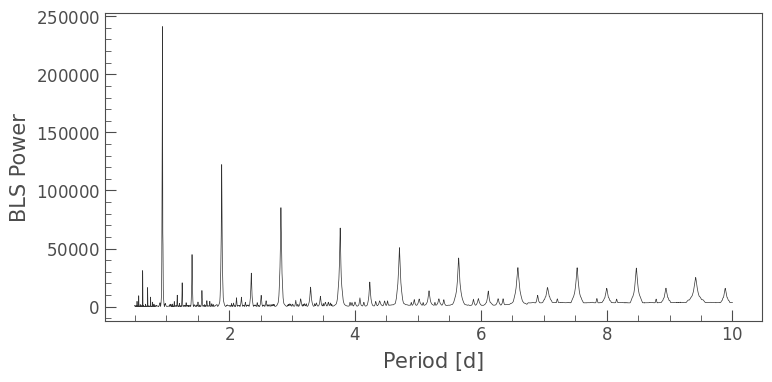

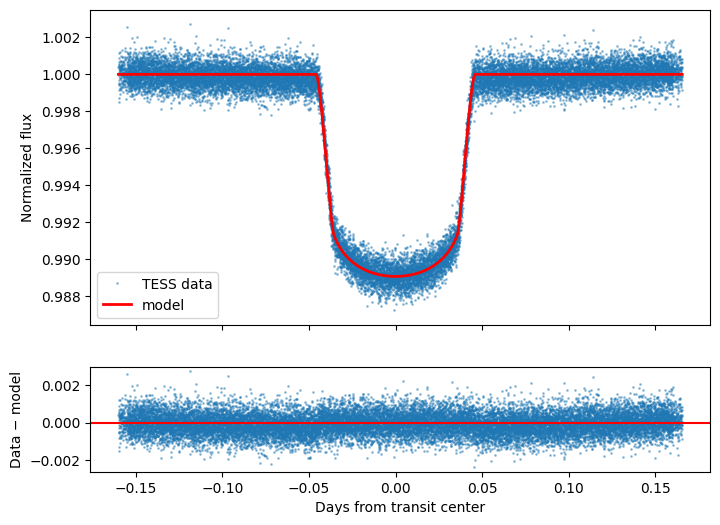


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
=== WASP-18 (4 sector(s)) ===
t0      = 1354.45791 ± 0.00003
period  = 0.94145 ± 0.00000
Rp/Rs   = 0.09923 ± 0.00018
a/Rs    = 3.41760 ± 0.01609
b       = 0.40643 ± 0.01215
u1      = 0.29049 ± 0.02436
u2      = 0.17145 ± 0.04382
inc     = 83.17 ± 0.24 deg
density = 0.85 ± 0.01 g/cm³

===== WASP-18: VETTING REPORT =====
Period = 0.94145 d | Rp/R★ = 0.0992 | depth = 1.09%
  Detection SNR      PASS  SNR = 1404
  Odd/even depths    PASS  0.1σ difference
  Secondary eclipse  PASS  487 ± 9 ppm (4.4% of transit)
  Density            PASS  transit / catalog = 1.23
  Planet size        PASS  Rp = 1.33 R_Jup
VERDICT: PLANET CANDIDATE (5/5 checks passed)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
=== WASP-121 (2 sector(s)) ===
t0      = 1491.99873 ± 0.00006
period  = 1.27492 ± 0.00000
Rp/Rs   = 0.12077 ± 0.00040
a/Rs    = 3.82789 ± 0.03101
b       = 0.02360 ± 0.42336
u1      = 0.22103 ± 0.02866
u2      = 0.24368 ± 0.06552
inc     = 89.6

In [12]:
w18 = analyze_star("WASP-18", n_sectors=4, plot=True, vet=True)
w121 = analyze_star("WASP-121", n_sectors=2, vet=True)

---
# Development notes
- Simple depth formula overestimates size → limb-darkened model needed
- Slightly wrong period smears folded transits → fit period and t0 too
- Residual patterns = model/data problem; random scatter = good fit
- TESS ramps after (and data issues before) gaps → trim 0.25 d on both sides
- Unmasked flattening distorts transits at segment edges → second, masked pass
- Fit b, not inclination; b stuck near 0 → profile-scan upper limit
- Search one sector, refine across sectors (period error grows over long baselines)
- Identical-twin binaries pass odd/even → caught by planet size check
- WASP-18 b and WASP-121 b show secondary eclipses (planet thermal emission);
  depths likely overestimated (ellipsoidal variation, unmasked flattening)

---
# To-do
- [ ] Batch run on 10–20 known planets → summary table of verdicts
- [ ] Per-transit depth check
- [ ] Secondary eclipse: mask eclipse in flattening; sloped baseline / phase-curve model
- [ ] Planet dayside temperature from eclipse depth
- [ ] Convert to pipeline.py for Claude Code
- [ ] ML classifier (from scratch in NumPy): planet vs false positive